# Lecture 4 — Class Exercise
## Scatter & Bubble Charts: Gapminder

> **Push to:** `week04/lecture04_exercise.ipynb`

**Rules:**
1. Colour used **sparingly** — one categorical variable, no rainbow
2. If showing all continents, either use accessible palette OR grey all + highlight one
3. `size_max` set when using bubble size
4. Log scale for GDP per capita
5. Insight title

---


In [1]:
import pandas as pd
import plotly.express as px


# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [2]:
# explore

print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


<class 'pandas.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   str    
 1   continent  1704 non-null   str    
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   str    
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), str(3)
memory usage: 135.3 KB
None
Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Continents: <ArrowStringArray>
['Asia', 'Europe', 'Africa', 'Americas', 'Oceania']
Length: 5, dtype: str
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.

## Task 1 — Scatter: life expectancy change over time

**What to build:** A scatter showing **GDP per capita vs life expectancy** for **two years** (2002 and 2007) to show how both moved — use **colour for year** (just 2 colours), **one continent only**.

Choose any continent except Africa (that was the example). Highlight the change direction.

> 💡 Filter: `df.loc[df['continent'] == 'YOUR_CHOICE']` then filter years


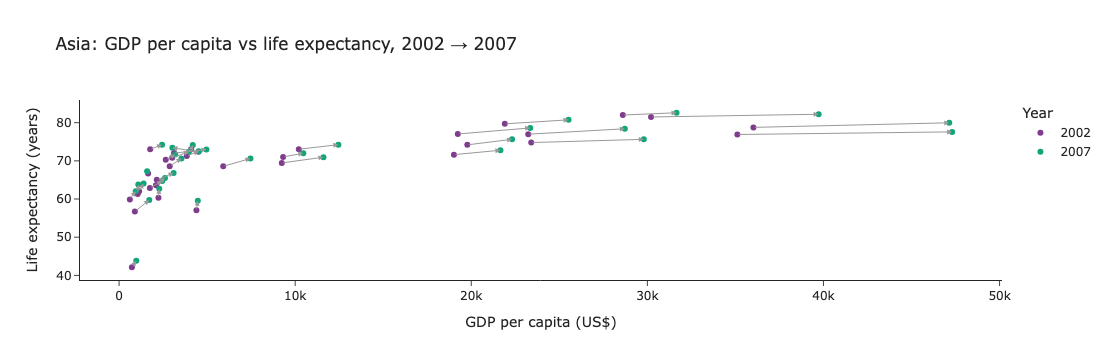

In [5]:
# Task 1
import plotly.express as px          

# STEP 1: keep only Asian countries and only the two years we compare.
asia = df.loc[(df['continent'] == 'Asia') & (df['year'].isin([2002, 2007]))].copy()

# STEP 2: turn year into text so Plotly gives exactly 2 colours.
asia['year_label'] = asia['year'].astype(str)

# STEP 3: the basic scatter. x = money, y = life expectancy.
fig = px.scatter(
    asia,
    x='gdpPercap',                   
    y='lifeExp',                     
    color='year_label',              
    #color_discrete_map={'2002': '#B0B0B0',   
     #                   '2007': '#1f77b4'}, 
    color_discrete_sequence=px.colors.qualitative.Bold ,
    hover_name='country',            
    title='Asia: GDP per capita vs life expectancy, 2002 → 2007',
    labels={'gdpPercap': 'GDP per capita (US$)',
            'lifeExp': 'Life expectancy (years)',
            'year_label': 'Year'},
)

# STEP 4: draw an arrow from each country's 2002 dot to its 2007 dot.
old = asia[asia['year'] == 2002].set_index('country')   
new = asia[asia['year'] == 2007].set_index('country')   

for country in old.index:                               
    fig.add_annotation(
        x=new.loc[country, 'gdpPercap'],   
        y=new.loc[country, 'lifeExp'],     
        ax=old.loc[country, 'gdpPercap'],  
        ay=old.loc[country, 'lifeExp'],    
        xref='x', yref='y',                
        axref='x', ayref='y',              
        showarrow=True,                 
        arrowhead=2,                      
        arrowwidth=1,                   
        arrowcolor='#999999',              
        text='',                          
    )

fig.update_layout(template='simple_white')   
fig.show()


## Task 2 — Bubble chart: tell a story

**What to build:** A bubble chart (full 2007 dataset, all countries) where:
- x = GDP per capita (log scale)
- y = life expectancy
- size = population
- colour = ONE continent highlighted (your choice), all others grey
- At least one annotation explaining the highlighted group's story

> This is the grey-and-highlight technique applied to a bubble chart.


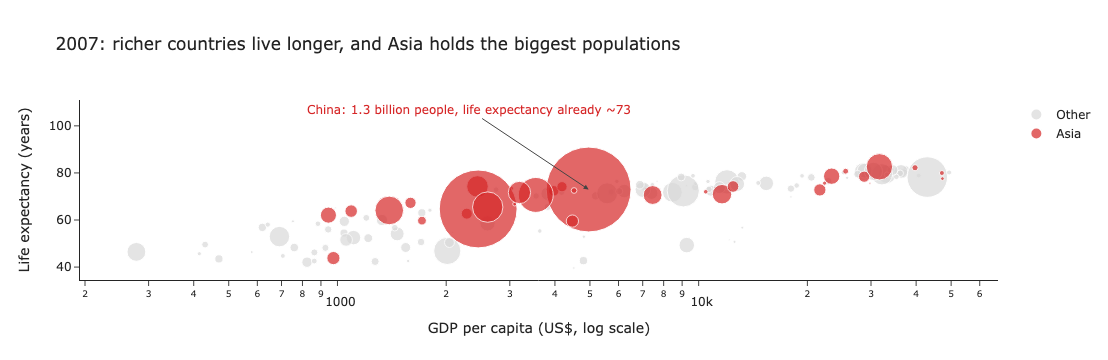

In [4]:
# Task 2
import numpy as np                   # needed for log10 in the annotation

# STEP 1: only the 2007 data, all countries.
d = df.loc[df['year'] == 2007].copy()

# STEP 2: make a simple label: "Asia" or "Other".
d['group'] = np.where(d['continent'] == 'Asia', 'Asia', 'Other')

# STEP 3: sort so the grey "Other" bubbles are drawn FIRST and Asia last.
d = d.sort_values('group', key=lambda s: s == 'Asia')

# STEP 4: the bubble chart.
fig = px.scatter(
    d,
    x='gdpPercap',                   
    y='lifeExp',                     
    size='pop',                      
    color='group',                   
    color_discrete_map={'Asia': '#d62728',    
                        'Other': '#D9D9D9'},  
    log_x=True,                      
    size_max=60,                     
    hover_name='country',            
    title='2007: richer countries live longer, and Asia holds the biggest populations',
    labels={'gdpPercap': 'GDP per capita (US$, log scale)',
            'lifeExp': 'Life expectancy (years)'},
)

# STEP 5: the annotation, which tells the story of the highlighted group.
china = d.loc[d['country'] == 'China'].iloc[0]    

fig.add_annotation(
    x=np.log10(china['gdpPercap']),  
    y=china['lifeExp'],              
    text='China: 1.3 billion people, life expectancy already ~73',
    showarrow=True,                  
    arrowhead=2,
    ax=-120, ay=-80,                 
    font=dict(color='#d62728', size=12),
)

fig.update_layout(template='simple_white', legend_title_text='')
fig.show()
